# Facial Feature Classification

## 1. Dataset Exploration


In [4]:
import pandas as pd

df = pd.read_csv("../data/train_labels.csv", dtype={"image_id": str})

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())
df.head()

Dataset shape: (63660, 2)

Columns: ['image_id', 'class']

Missing values:
image_id    0
class       0
dtype: int64


,image_id,class
0,00001,DogEye
1,00002,DogMouth
2,00003,DogFace
3,00004,DogNose
4,00005,DogNose


In [5]:
class_counts = df["class"].value_counts()

print("Number of classes:", df["class"].nunique())
print("\nImages per class:")
print(class_counts)

Number of classes: 8

Images per class:
class
CatEye      13884
DogEye      11580
CatNose      6942
CatFace      6942
CatMouth     6942
DogMouth     5790
DogFace      5790
DogNose      5790
Name: count, dtype: int64


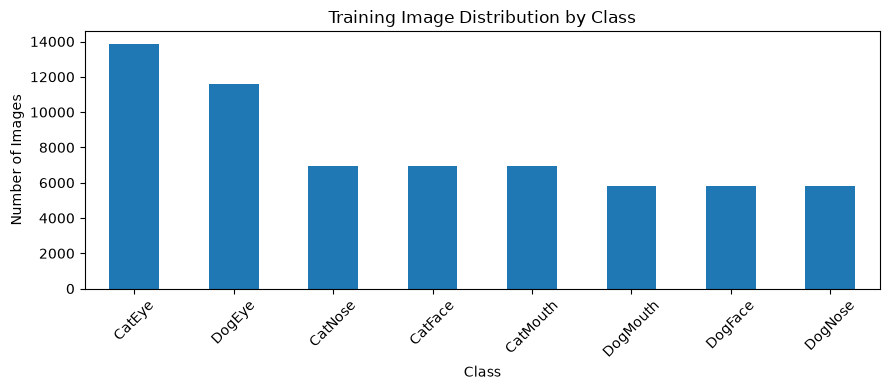

In [6]:
import matplotlib.pyplot as plt

class_counts.plot(kind="bar", figsize=(9, 4))
plt.title("Training Image Distribution by Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

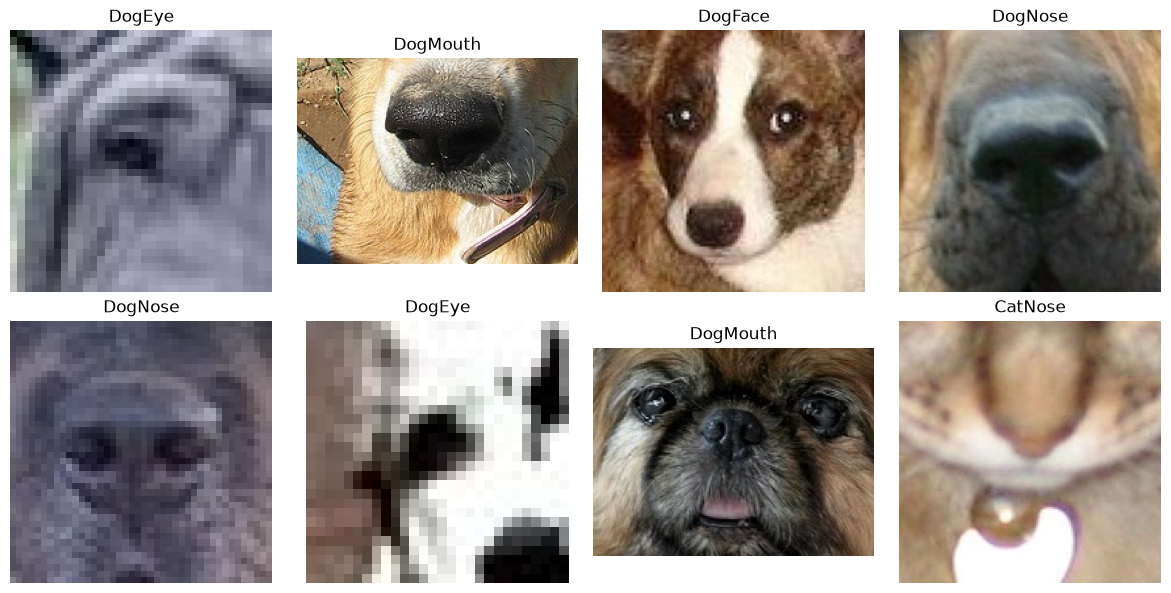

In [7]:
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

train_dir = Path("../data/train/train")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, (_, row) in zip(axes.flat, df.head(8).iterrows()):
    image_path = train_dir / f"{row['image_id']}.jpg"
    image = Image.open(image_path)
    ax.imshow(image)
    ax.set_title(row["class"])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
image_sizes = []

for image_id in df["image_id"].head(100):
    image_path = train_dir / f"{image_id}.jpg"

    with Image.open(image_path) as image:
        image_sizes.append(image.size)

print("Different image dimensions:", set(image_sizes))

Different image dimensions: {(256, 288), (56, 56), (70, 70), (52, 52), (116, 116), (38, 38), (20, 20), (94, 70), (112, 112), (176, 176), (176, 124), (66, 66), (54, 40), (130, 130), (140, 140), (34, 34), (48, 48), (64, 47), (64, 44), (158, 158), (171, 210), (30, 30), (62, 62), (104, 77), (166, 116), (316, 222), (108, 108), (26, 26), (86, 86), (112, 163), (94, 66), (191, 191), (68, 50), (40, 40), (34, 24), (178, 178), (114, 114), (68, 68), (149, 148), (132, 132), (207, 232), (36, 36), (54, 54), (100, 100), (110, 110), (78, 54), (32, 32), (96, 96), (128, 128), (64, 64), (122, 90), (266, 266), (158, 117), (387, 388), (188, 182), (60, 60), (82, 82), (343, 376), (78, 78), (182, 135), (478, 585), (24, 24), (97, 97), (106, 106), (98, 68), (142, 105), (28, 28), (74, 74), (155, 154), (157, 157), (250, 358), (148, 148), (50, 37), (90, 64), (214, 157), (42, 42)}


In [9]:
missing_images = [
    image_id for image_id in df["image_id"]
    if not (train_dir / f"{image_id}.jpg").exists()
]

print("Missing training images:", len(missing_images))

Missing training images: 0


## 2. Data Preprocessing

### 2.1 Training and Validation Split

In [10]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["class"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

Training images: 50928
Validation images: 12732


In [11]:
import tensorflow as tf

class_names = sorted(df["class"].unique())
class_to_index = {name: i for i, name in enumerate(class_names)}

train_paths = [str(train_dir / f"{image_id}.jpg") for image_id in train_df["image_id"]]
val_paths = [str(train_dir / f"{image_id}.jpg") for image_id in val_df["image_id"]]

train_labels = train_df["class"].map(class_to_index).to_numpy()
val_labels = val_df["class"].map(class_to_index).to_numpy()

print(class_to_index)
print("Training paths:", len(train_paths))
print("Validation paths:", len(val_paths))

{'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}
Training paths: 50928
Validation paths: 12732


In [12]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize_with_pad(image, 128, 128)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

train_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
val_ds = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))

train_ds = train_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

train_ds = train_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [13]:
for images, labels in train_ds.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Pixel range:", float(tf.reduce_min(images)), float(tf.reduce_max(images)))

Images shape: (32, 128, 128, 3)
Labels shape: (32,)
Pixel range: 0.0 1.0


## 3. CNN Model Development
### 3.1 Baseline CNN

In [14]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(8, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,672 (12.61 MB)

 Trainable params: 3,305,672 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

### 3.2 Compile and Train Baseline CNN

In [15]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [16]:
train_ds = train_ds.shuffle(5000, seed=42)

In [17]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5


/Users/chaimaoueslati/Desktop/Data ENG and AI/data_ai_foundations/facial_feature_classifier/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1592/1592 ━━━━━━━━━━━━━━━━━━━━ 267s 162ms/step - accuracy: 0.9266 - loss: 0.2282 - val_accuracy: 0.9665 - val_loss: 0.1060
Epoch 2/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 249s 151ms/step - accuracy: 0.9729 - loss: 0.0825 - val_accuracy: 0.9779 - val_loss: 0.0709
Epoch 3/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 238s 146ms/step - accuracy: 0.9843 - loss: 0.0462 - val_accuracy: 0.9732 - val_loss: 0.0849
Epoch 4/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 234s 143ms/step - accuracy: 0.9884 - loss: 0.0339 - val_accuracy: 0.9728 - val_loss: 0.0998
Epoch 5/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 230s 141ms/step - accuracy: 0.9915 - loss: 0.0232 - val_accuracy: 0.9732 - val_loss: 0.1216


### Experiment 1: Baseline 

**Configuration**
- Input image size: 128 × 128 × 3
- Batch size: 32
- 3 convolutional layers (32, 64, 128 filters), max pooling, flatten, dense layer (128 neurons), softmax output (8 classes)
- Optimiser: Adam
- Learning rate: 0.001
- Loss function: Sparse categorical crossentropy
- Epochs: 5
- Training images: 50,928
- Validation images: 12,732

**Results**
| Epoch | Train accuracy | Validation accuracy | Train loss | Validation loss |
|---|---|---|---|---|
| 1 | 92.66% | 96.65% | 0.2282 | 0.1060 |
| 2 | 97.29% | 97.79% | 0.0825 | 0.0709 |
| 3 | 98.43% | 97.32% | 0.0462 | 0.0849 |
| 4 | 98.84% | 97.28% | 0.0339 | 0.0998 |
| 5 | 99.15% | 97.32% | 0.0232 | 0.1216 |

Epoch 2 had the highest validation accuracy and lowest validation loss in this run. Later epochs continued to improve training performance while validation loss increased.

